# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Zico Diego Rio Ramadhonny | 5054251023 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [21]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import os
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import seaborn as sns
import kagglehub as kg
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RANDOM_STATE = 42

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print(f"Device: {DEVICE}")

Device: cuda


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

url = "zalando-research/fashionmnist"

path = kg.dataset_download(url)
print("Path to dataset files:", path)

dataset_file = []
files_in_path = [os.path.join(path, file) for file in os.listdir(path)]
for file in files_in_path:
    if os.path.isfile(file) and os.path.splitext(os.path.basename(file))[-1] == ".csv":
        dataset_file.append(file)
    
if dataset_file is None:
    raise FileNotFoundError(f"CSV dataset file can't be found at {path}.")

train_path, test_path = None, None
for file in dataset_file:
    if file.endswith("train.csv"):
        train_path = file
    else:
        test_path = file
        
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (60000, 785)
Test: (10000, 785)


<Axes: >

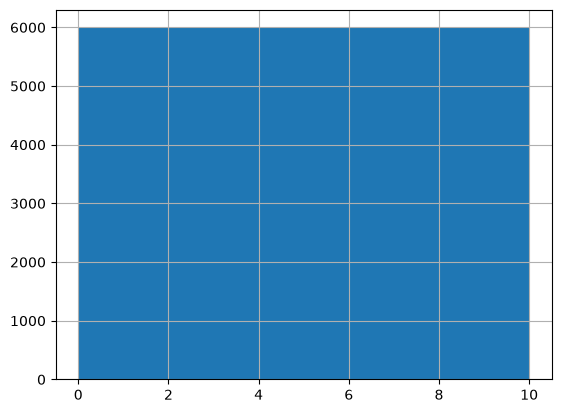

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

DATASET_MAP = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

display(train_df["label"].hist(bins=range(0, 11)))

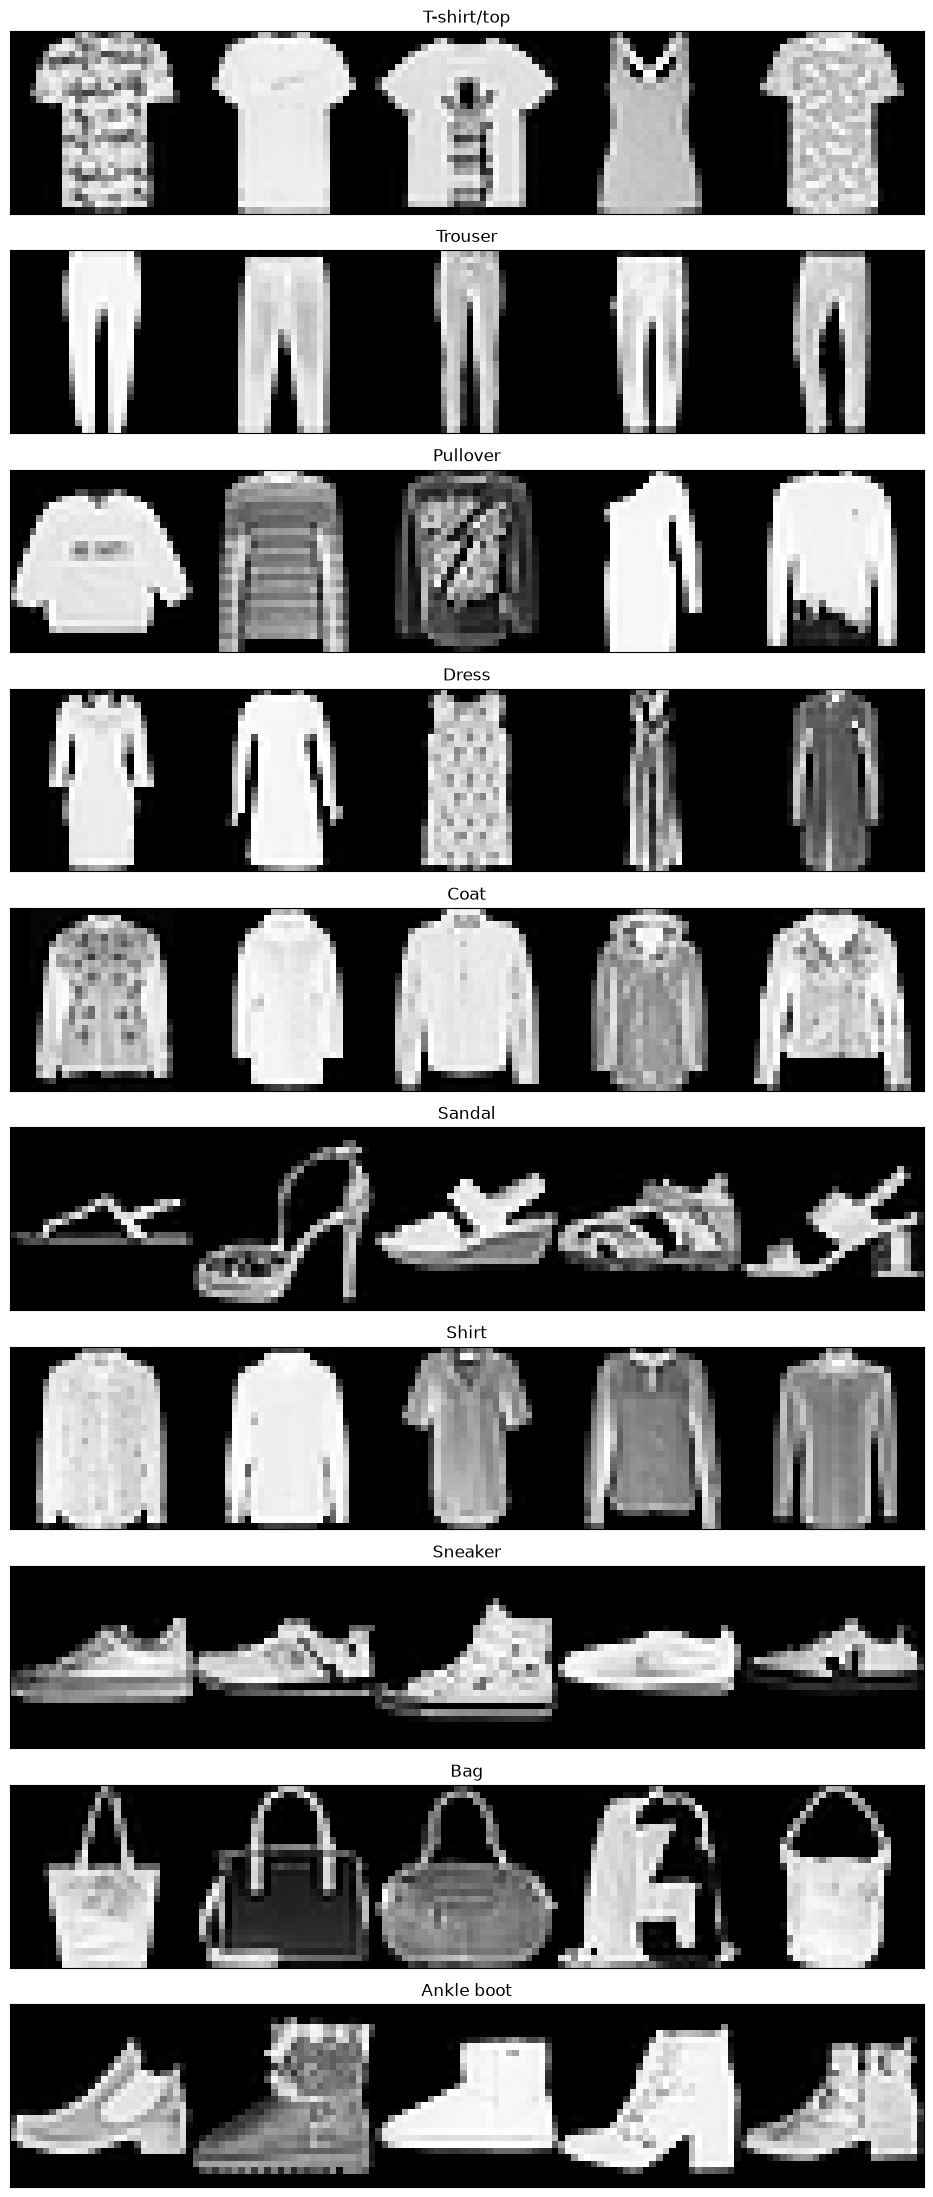

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

def construct_img_from_row(df, row_id):
    pixel_data = df.loc[row_id]
    img_array = []
    
    for i in range(28):
        offset_pixel = 28 * i
        curr_pixel_row = []
        
        for j in range(1, 29):
            curr_pixel_row.append(pixel_data[f"pixel{j + offset_pixel}"])
        
        img_array.append(curr_pixel_row)            

    return np.array(img_array)

fig, ax = plt.subplots(nrows=10, ncols=1, figsize=(14, 28))
ax = ax.flatten()

for i in range(10):
    curr_cls_five_imgs = train_df.loc[train_df["label"] == i].reset_index(drop=True).head()
    img_arrays = np.concat([construct_img_from_row(curr_cls_five_imgs, j) for j in range(len(curr_cls_five_imgs))], axis=1)
    ax[i].imshow(img_arrays, cmap="Grays_r")
    ax[i].grid(visible=False)
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    ax[i].set_title(f"{DATASET_MAP[i]}")

**Jawaban:** Kelas yang secara visual mirip antara lain **T-shirt/top, Shirt, Pullover, dan Coat** (semuanya atasan dengan siluet serupa), serta **Sandal, Sneaker, dan Ankle boot** (semuanya alas kaki). *Dress* juga kadang mirip dengan *T-shirt/top* atau *Coat*.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Missing value train: 0
Missing value test : 0
Rentang piksel     : 0 - 255
Rata-rata piksel   : 72.9568306122449

Jumlah gambar per kelas (train):


label
Ankle boot     6000
Bag            6000
Coat           6000
Dress          6000
Pullover       6000
Sandal         6000
Shirt          6000
Sneaker        6000
T-shirt/top    6000
Trouser        6000
Name: count, dtype: int64

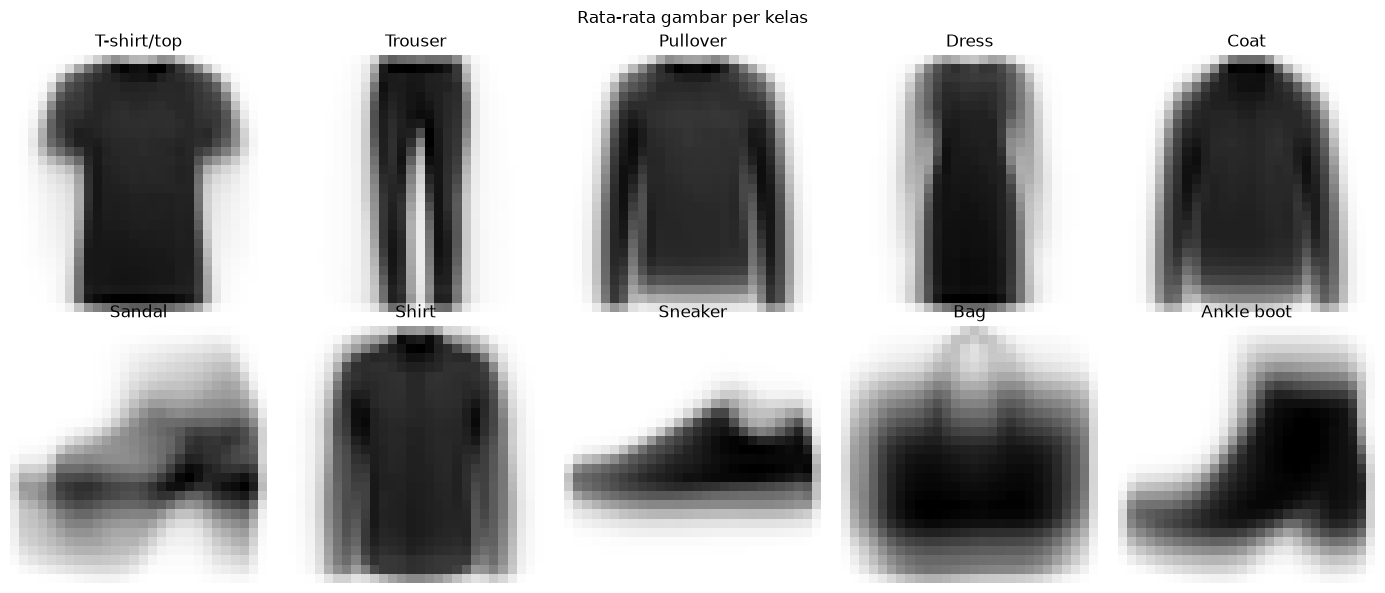

In [5]:
# EDA tambahan: nilai kosong, statistik piksel, dan rata-rata gambar per kelas.
print("Missing value train:", train_df.isna().sum().sum())
print("Missing value test :", test_df.isna().sum().sum())
print("Rentang piksel     :", train_df.drop(columns="label").values.min(), "-", train_df.drop(columns="label").values.max())
print("Rata-rata piksel   :", train_df.drop(columns="label").values.mean())

print("\nJumlah gambar per kelas (train):")
display(train_df["label"].map(DATASET_MAP).value_counts().sort_index())

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flatten()):
    mean_img = train_df.loc[train_df["label"] == i].drop(columns="label").mean().values.reshape(28, 28)
    ax.imshow(mean_img, cmap="gray_r")
    ax.set_title(DATASET_MAP[i])
    ax.axis("off")
plt.suptitle("Rata-rata gambar per kelas")
plt.tight_layout()
plt.show()

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

X = train_df.drop(columns=["label"])
y = train_df["label"]

In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X = X / 255
display(X.head())

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.019608,0.0,0.0,...,0.000000,0.0,0.0,0.117647,0.168627,0.000000,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.003922,0.007843,0.0,0.0,0.000000,0.0,0.0,...,0.011765,0.0,0.0,0.000000,0.000000,0.003922,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=RANDOM_STATE, stratify=y)
X_test, y_test = test_df.drop(columns=["label"]), test_df["label"]

X_test = X_test / 255

In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

from torch.utils.data import TensorDataset

def to_tensors(x_df, y_sr):
    X_t = torch.tensor(x_df.values, dtype=torch.float32).reshape(-1, 1, 28, 28)
    y_t = torch.tensor(y_sr.values, dtype=torch.long)
    return X_t, y_t

X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)

BATCH_SIZE = 128

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

print("Train:", X_train_t.shape, y_train_t.shape)
print("Val  :", X_val_t.shape, y_val_t.shape)
print("Test :", X_test_t.shape, y_test_t.shape)

Train: torch.Size([54000, 1, 28, 28]) torch.Size([54000])
Val  : torch.Size([6000, 1, 28, 28]) torch.Size([6000])
Test : torch.Size([10000, 1, 28, 28]) torch.Size([10000])


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).


class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


torch.manual_seed(RANDOM_STATE)
ann_model = ANN().to(DEVICE)
print(ann_model)
print("Jumlah parameter ANN:", count_params(ann_model))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter ANN: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.


LEARNING_RATE = 1e-3
EPOCHS = 100
criterion = nn.CrossEntropyLoss()


def evaluate(model, loader):
    """Hitung loss & accuracy pada loader (mode eval, tanpa gradient)."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            total_loss += criterion(out, yb).item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n


def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        model.train()  # penting untuk BatchNorm & Dropout
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        # metrik di akhir epoch (mode eval)
        tr_loss, tr_acc = evaluate(model, train_loader)
        va_loss, va_acc = evaluate(model, val_loader)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        print(f"Epoch {epoch:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}")

    return history


ann_history = train_model(ann_model, train_loader, val_loader)

Epoch 01/100 | train loss 0.4325 acc 0.8451 | val loss 0.4435 acc 0.8400
Epoch 02/100 | train loss 0.3848 acc 0.8590 | val loss 0.4170 acc 0.8480
Epoch 03/100 | train loss 0.3257 acc 0.8820 | val loss 0.3592 acc 0.8703
Epoch 04/100 | train loss 0.3036 acc 0.8903 | val loss 0.3502 acc 0.8760
Epoch 05/100 | train loss 0.2868 acc 0.8958 | val loss 0.3355 acc 0.8792
Epoch 06/100 | train loss 0.2696 acc 0.8998 | val loss 0.3271 acc 0.8797
Epoch 07/100 | train loss 0.2771 acc 0.8962 | val loss 0.3426 acc 0.8743
Epoch 08/100 | train loss 0.2543 acc 0.9046 | val loss 0.3275 acc 0.8835
Epoch 09/100 | train loss 0.2483 acc 0.9087 | val loss 0.3343 acc 0.8800
Epoch 10/100 | train loss 0.2608 acc 0.9011 | val loss 0.3477 acc 0.8700
Epoch 11/100 | train loss 0.2168 acc 0.9200 | val loss 0.3182 acc 0.8902
Epoch 12/100 | train loss 0.2250 acc 0.9155 | val loss 0.3228 acc 0.8868
Epoch 13/100 | train loss 0.1994 acc 0.9273 | val loss 0.3161 acc 0.8917
Epoch 14/100 | train loss 0.2193 acc 0.9181 | val l

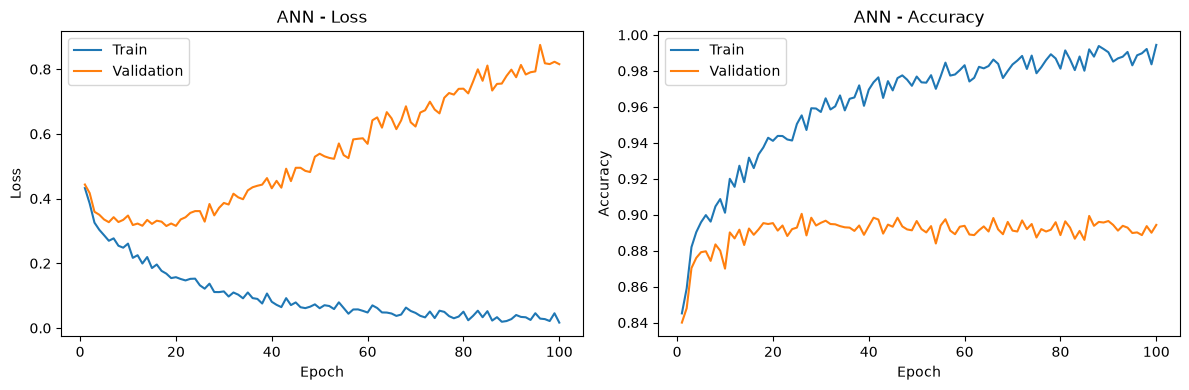

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epochs, history["train_loss"], label="Train")
    ax[0].plot(epochs, history["val_loss"], label="Validation")
    ax[0].set_title(f"{title} - Loss")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    ax[1].plot(epochs, history["train_acc"], label="Train")
    ax[1].plot(epochs, history["val_acc"], label="Validation")
    ax[1].set_title(f"{title} - Accuracy")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Accuracy")
    ax[1].legend()

    plt.tight_layout()
    plt.show()


plot_history(ann_history, "ANN")

In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.


def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(DEVICE)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()


y_true = y_test_t.numpy()
ann_pred = predict(ann_model, test_loader)
print("Test accuracy ANN:", (ann_pred == y_true).mean())

Test accuracy ANN: 0.9005


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.


# Perhitungan manual ukuran output (rumus: (W - K + 2P) / S + 1)
#   Input                         : 1  x 28 x 28
#   Conv2d(1, 32, k=3, p=1, s=1)  : (28 - 3 + 2*1)/1 + 1 = 28  -> 32 x 28 x 28
#   MaxPool2d(2)                  : (28 - 2 + 0)/2 + 1   = 14  -> 32 x 14 x 14
#   Conv2d(32, 64, k=3, p=1, s=1) : (14 - 3 + 2*1)/1 + 1 = 14  -> 64 x 14 x 14
#   MaxPool2d(2)                  : (14 - 2 + 0)/2 + 1   = 7   -> 64 x 7 x 7
#   Flatten                       : 64 * 7 * 7 = 3136  -> input Linear pertama


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(RANDOM_STATE)
cnn_model = SimpleCNN().to(DEVICE)
print(cnn_model)
print("Jumlah parameter CNN sederhana:", count_params(cnn_model))

# Verifikasi dengan tensor dummy
dummy = torch.zeros(1, 1, 28, 28).to(DEVICE)
with torch.no_grad():
    x = dummy
    for layer in cnn_model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:<10} -> {tuple(x.shape)}")
    print("Setelah Flatten:", x.flatten(1).shape)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN sederhana: 421642
Conv2d     -> (1, 32, 28, 28)
ReLU       -> (1, 32, 28, 28)
MaxPool2d  -> (1, 32, 14, 14)
Conv2d     -> (1, 64, 14, 14)
ReLU       -> (1, 64, 14, 14)
MaxPool2d  -> (1, 64, 7, 7)
Setelah Flatten: torch.Size([1, 3136])


Epoch 01/100 | train loss 0.3956 acc 0.8556 | val loss 0.4043 acc 0.8548
Epoch 02/100 | train loss 0.2907 acc 0.8963 | val loss 0.3127 acc 0.8865
Epoch 03/100 | train loss 0.2466 acc 0.9110 | val loss 0.2747 acc 0.9013
Epoch 04/100 | train loss 0.2521 acc 0.9073 | val loss 0.2857 acc 0.8962
Epoch 05/100 | train loss 0.2175 acc 0.9219 | val loss 0.2663 acc 0.9052
Epoch 06/100 | train loss 0.1988 acc 0.9270 | val loss 0.2435 acc 0.9088
Epoch 07/100 | train loss 0.1852 acc 0.9329 | val loss 0.2459 acc 0.9088
Epoch 08/100 | train loss 0.1683 acc 0.9409 | val loss 0.2371 acc 0.9110
Epoch 09/100 | train loss 0.1572 acc 0.9434 | val loss 0.2373 acc 0.9108
Epoch 10/100 | train loss 0.1410 acc 0.9491 | val loss 0.2319 acc 0.9167
Epoch 11/100 | train loss 0.1307 acc 0.9535 | val loss 0.2350 acc 0.9138
Epoch 12/100 | train loss 0.1273 acc 0.9518 | val loss 0.2521 acc 0.9133
Epoch 13/100 | train loss 0.1024 acc 0.9649 | val loss 0.2343 acc 0.9170
Epoch 14/100 | train loss 0.0808 acc 0.9727 | val l

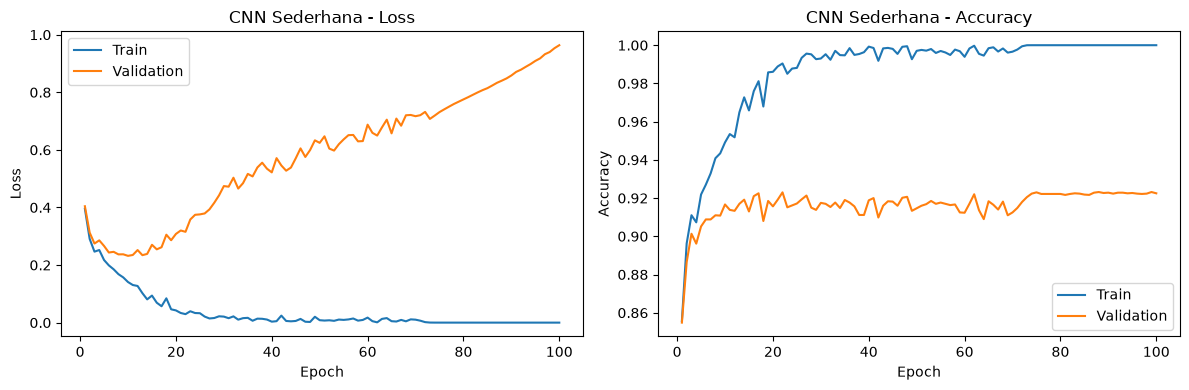

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.


cnn_history = train_model(cnn_model, train_loader, val_loader)
plot_history(cnn_history, "CNN Sederhana")

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.


cnn_pred = predict(cnn_model, test_loader)
print("Test accuracy CNN sederhana:", (cnn_pred == y_true).mean())

Test accuracy CNN sederhana: 0.9312


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.


class BNDropoutCNN(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(RANDOM_STATE)
cnn_bn_model = BNDropoutCNN(dropout=0.5).to(DEVICE)
print(cnn_bn_model)
print("Jumlah parameter CNN + BN + Dropout:", count_params(cnn_bn_model))

BNDropoutCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN + BN + Dropout: 421834


Epoch 01/100 | train loss 0.3128 acc 0.8847 | val loss 0.3307 acc 0.8807
Epoch 02/100 | train loss 0.2543 acc 0.9077 | val loss 0.2869 acc 0.8983
Epoch 03/100 | train loss 0.2318 acc 0.9151 | val loss 0.2749 acc 0.9042
Epoch 04/100 | train loss 0.2249 acc 0.9162 | val loss 0.2810 acc 0.8983
Epoch 05/100 | train loss 0.1907 acc 0.9296 | val loss 0.2478 acc 0.9108
Epoch 06/100 | train loss 0.1805 acc 0.9315 | val loss 0.2408 acc 0.9123
Epoch 07/100 | train loss 0.1594 acc 0.9394 | val loss 0.2406 acc 0.9145
Epoch 08/100 | train loss 0.1540 acc 0.9432 | val loss 0.2311 acc 0.9198
Epoch 09/100 | train loss 0.1502 acc 0.9439 | val loss 0.2344 acc 0.9157
Epoch 10/100 | train loss 0.1409 acc 0.9472 | val loss 0.2326 acc 0.9170
Epoch 11/100 | train loss 0.1259 acc 0.9522 | val loss 0.2346 acc 0.9183
Epoch 12/100 | train loss 0.1386 acc 0.9475 | val loss 0.2409 acc 0.9137
Epoch 13/100 | train loss 0.1129 acc 0.9584 | val loss 0.2378 acc 0.9163
Epoch 14/100 | train loss 0.0977 acc 0.9641 | val l

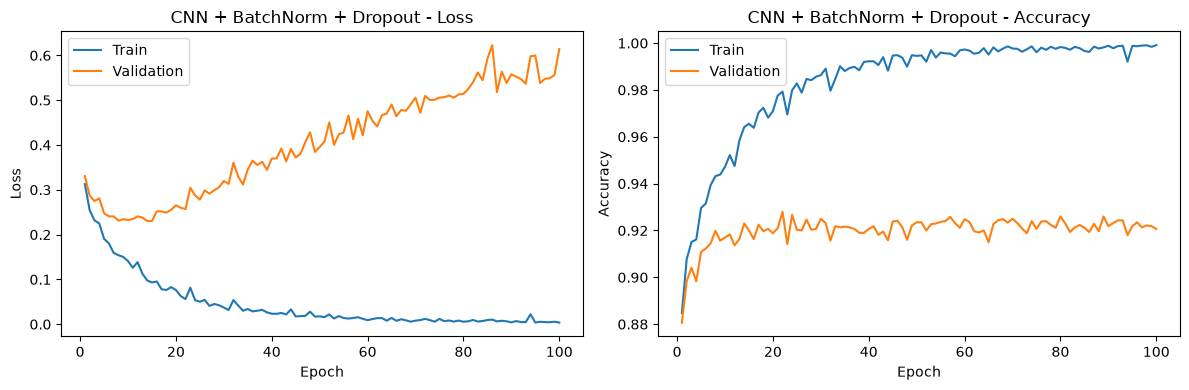

CNN sederhana        | selisih akurasi train - val (epoch terakhir): 0.0775
CNN + BN + Dropout   | selisih akurasi train - val (epoch terakhir): 0.0784


In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.


# train_model() sudah memanggil model.train() sebelum update bobot
# dan evaluate() memanggil model.eval() saat menghitung metrik.
cnn_bn_history = train_model(cnn_bn_model, train_loader, val_loader)
plot_history(cnn_bn_history, "CNN + BatchNorm + Dropout")

for name, h in [("CNN sederhana", cnn_history), ("CNN + BN + Dropout", cnn_bn_history)]:
    gap = h["train_acc"][-1] - h["val_acc"][-1]
    print(f"{name:<20} | selisih akurasi train - val (epoch terakhir): {gap:.4f}")

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.


cnn_bn_pred = predict(cnn_bn_model, test_loader)
print("Test accuracy CNN + BN + Dropout:", (cnn_bn_pred == y_true).mean())

Test accuracy CNN + BN + Dropout: 0.928


# 4. Evaluasi Model

In [22]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

models = {
    "ANN": ann_model,
    "CNN Sederhana": cnn_model,
    "CNN + BN + Dropout": cnn_bn_model,
}
preds = {
    "ANN": ann_pred,
    "CNN Sederhana": cnn_pred,
    "CNN + BN + Dropout": cnn_bn_pred,
}

rows = []
for name, p in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, p),
        "Precision (macro)": precision_score(y_true, p, average="macro"),
        "Recall (macro)": recall_score(y_true, p, average="macro"),
        "F1-Score (macro)": f1_score(y_true, p, average="macro"),
        "Jumlah Parameter": count_params(models[name]),
    })

results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision (macro)": "{:.4f}",
    "Recall (macro)": "{:.4f}", "F1-Score (macro)": "{:.4f}",
    "Jumlah Parameter": "{:,}",
}))

best_name = results_df["F1-Score (macro)"].idxmax()
best_model = models[best_name]
best_pred = preds[best_name]
print("Model terbaik:", best_name)

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter
Model,,,,,
ANN,0.9005,0.9004,0.9005,0.8998,"235,146"
CNN Sederhana,0.9312,0.9311,0.9312,0.9311,"421,642"
CNN + BN + Dropout,0.9280,0.9279,0.9280,0.9277,"421,834"


Model terbaik: CNN Sederhana


In [23]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.


class_names = [DATASET_MAP[i] for i in range(10)]
print(f"Classification report - {best_name}")
print(classification_report(y_true, best_pred, target_names=class_names, digits=4))

Classification report - CNN Sederhana
              precision    recall  f1-score   support

 T-shirt/top     0.8750    0.8890    0.8819      1000
     Trouser     0.9900    0.9910    0.9905      1000
    Pullover     0.9025    0.8790    0.8906      1000
       Dress     0.9307    0.9400    0.9353      1000
        Coat     0.8939    0.9100    0.9019      1000
      Sandal     0.9889    0.9800    0.9844      1000
       Shirt     0.8235    0.8070    0.8152      1000
     Sneaker     0.9639    0.9620    0.9630      1000
         Bag     0.9850    0.9840    0.9845      1000
  Ankle boot     0.9576    0.9700    0.9637      1000

    accuracy                         0.9312     10000
   macro avg     0.9311    0.9312    0.9311     10000
weighted avg     0.9311    0.9312    0.9311     10000



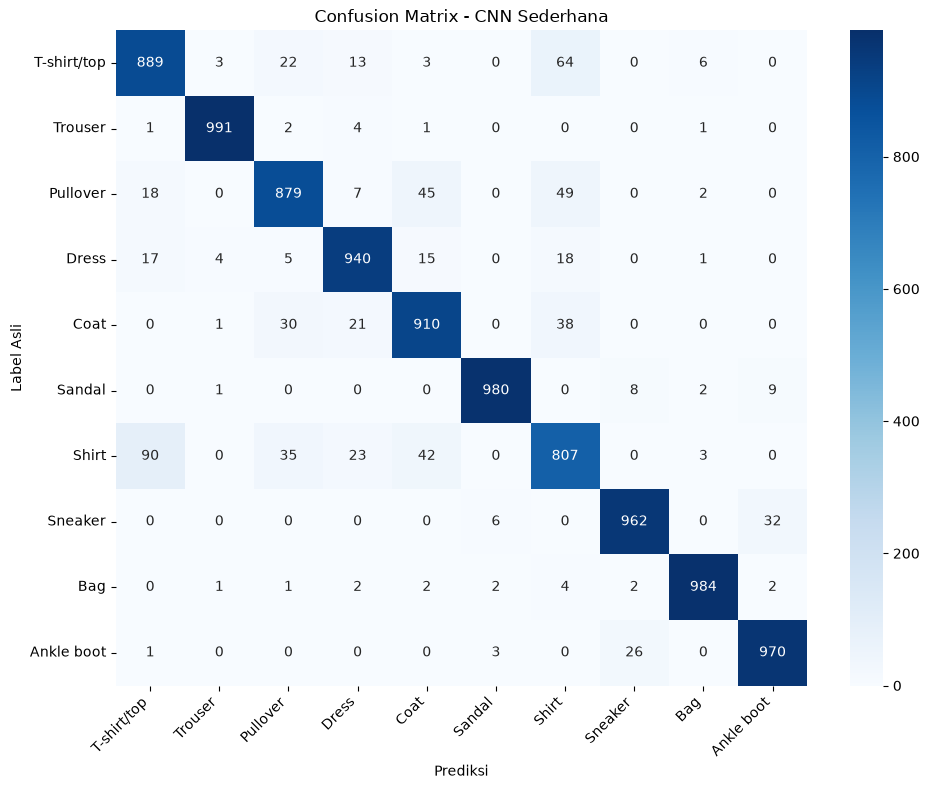

5 kesalahan terbanyak (label asli -> prediksi):
  Shirt        -> T-shirt/top : 90 gambar
  T-shirt/top  -> Shirt       : 64 gambar
  Pullover     -> Shirt       : 49 gambar
  Pullover     -> Coat        : 45 gambar
  Shirt        -> Coat        : 42 gambar


In [24]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?


cm = confusion_matrix(y_true, best_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Label Asli")
plt.title(f"Confusion Matrix - {best_name}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Pasangan kelas yang paling sering tertukar (abaikan diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top_pairs = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]
print("5 kesalahan terbanyak (label asli -> prediksi):")
for t, p in top_pairs:
    print(f"  {class_names[t]:<12} -> {class_names[p]:<12}: {cm_off[t, p]} gambar")

Jumlah salah klasifikasi: 688 dari 10000


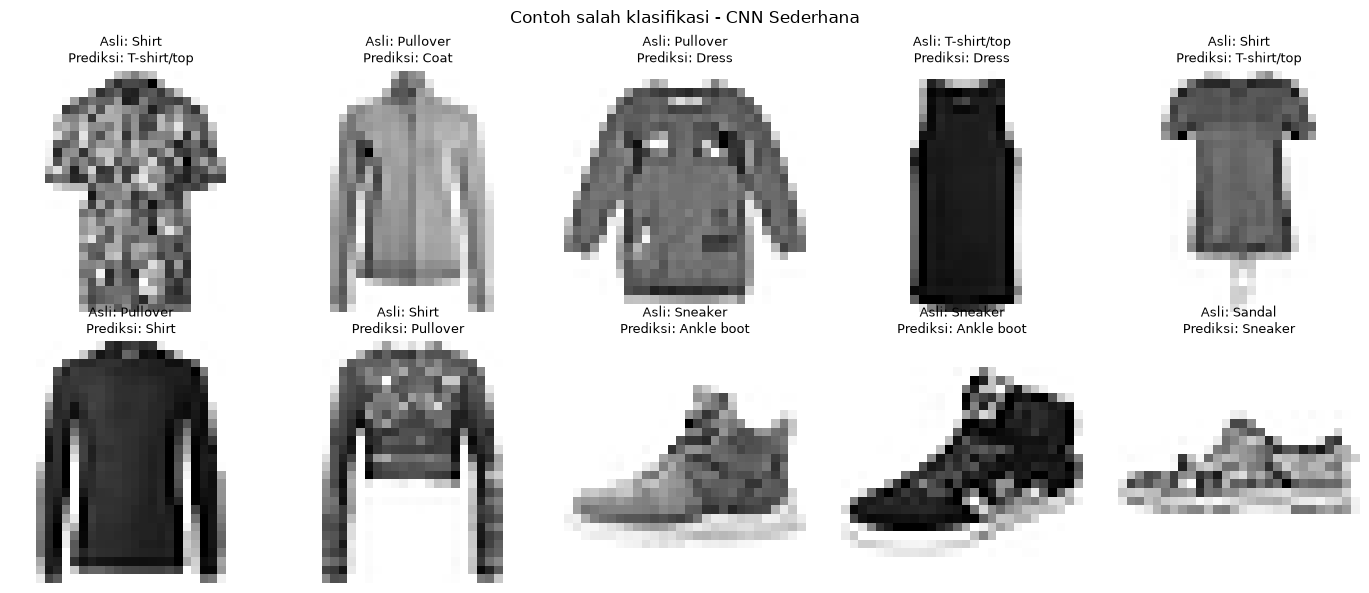

In [25]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.


wrong_idx = np.where(best_pred != y_true)[0]
print(f"Jumlah salah klasifikasi: {len(wrong_idx)} dari {len(y_true)}")

rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(wrong_idx, size=min(10, len(wrong_idx)), replace=False)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.flatten(), sample_idx):
    ax.imshow(X_test_t[i, 0].numpy(), cmap="gray_r")
    ax.set_title(f"Asli: {class_names[y_true[i]]}\nPrediksi: {class_names[best_pred[i]]}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Contoh salah klasifikasi - {best_name}")
plt.tight_layout()
plt.show()

Feature map dari model: CNN Sederhana


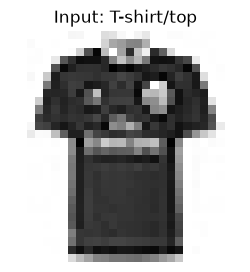

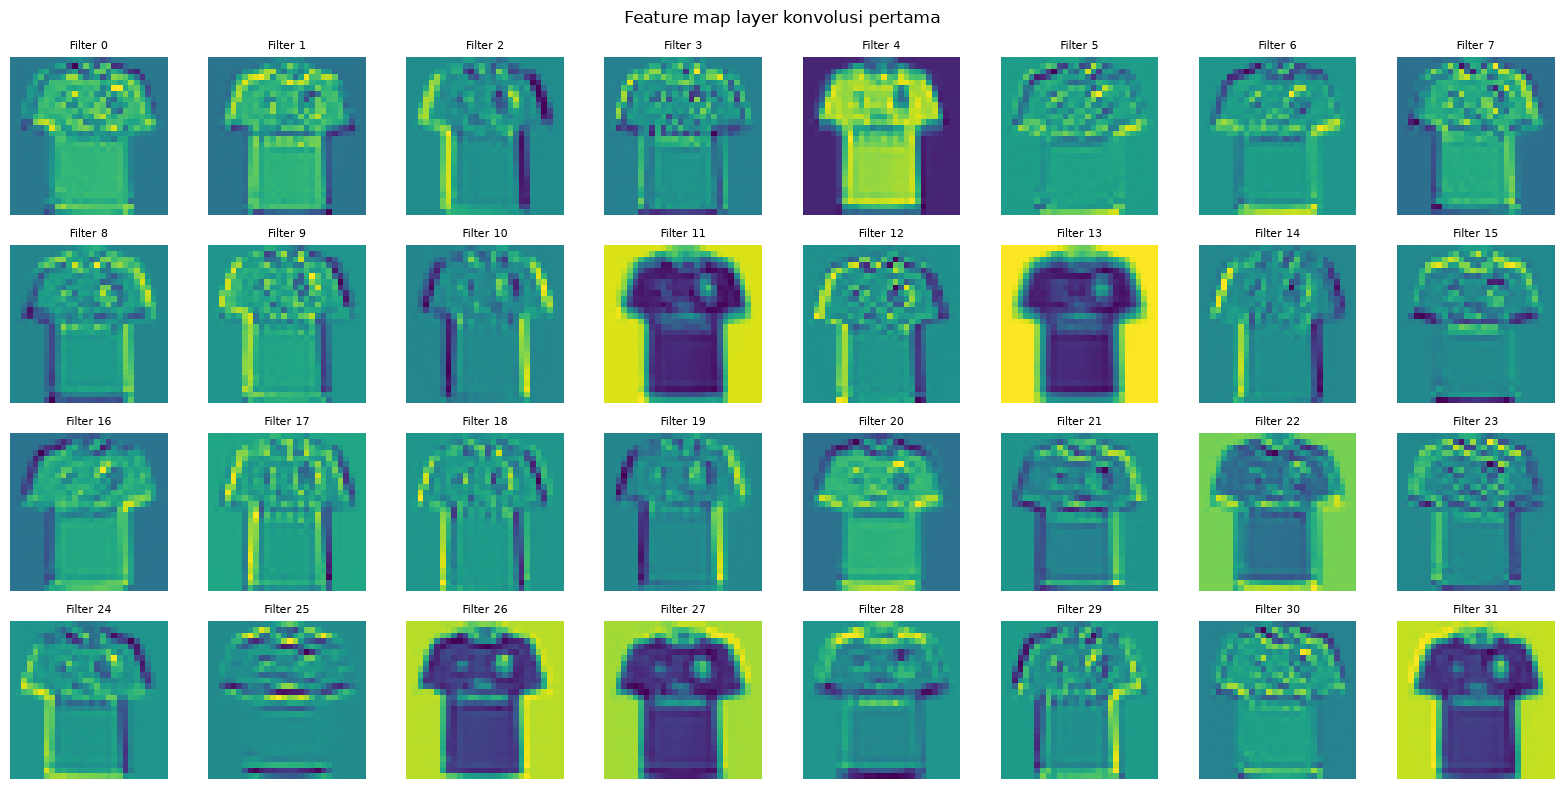

In [26]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?


# Feature map hanya ada pada model CNN. Jika model terbaik adalah ANN, pakai CNN terbaik.
if hasattr(best_model, "features"):
    fmap_name, fmap_model = best_name, best_model
else:
    cnn_only = results_df.loc[["CNN Sederhana", "CNN + BN + Dropout"], "F1-Score (macro)"]
    fmap_name = cnn_only.idxmax()
    fmap_model = models[fmap_name]
print("Feature map dari model:", fmap_name)

fmap_model.eval()
x = X_test_t[0:1].to(DEVICE)  # (1, 1, 28, 28)
with torch.no_grad():
    fmap = fmap_model.features[0](x)[0].detach().cpu().numpy()  # (32, 28, 28)

plt.figure(figsize=(3, 3))
plt.imshow(X_test_t[0, 0].numpy(), cmap="gray_r")
plt.title(f"Input: {class_names[y_true[0]]}")
plt.axis("off")
plt.show()

n_filters = fmap.shape[0]
cols = 8
rows = int(np.ceil(n_filters / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 2 * rows))
for k, ax in enumerate(axes.flatten()):
    if k < n_filters:
        ax.imshow(fmap[k], cmap="viridis")
        ax.set_title(f"Filter {k}", fontsize=8)
    ax.axis("off")
plt.suptitle("Feature map layer konvolusi pertama")
plt.tight_layout()
plt.show()

In [ ]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.


import inspect

torch.save(best_model.state_dict(), "model.pth")
print(f"Bobot model '{best_name}' disimpan ke model.pth")

# Simpan definisi class model agar bisa dimuat ulang pada tugas Deployment
try:
    class_source = inspect.getsource(type(best_model))
    with open("model_def.py", "w") as f:
        f.write("import torch\nimport torch.nn as nn\n\n\n" + class_source)
    print(f"Definisi class {type(best_model).__name__} disimpan ke model_def.py")
except (OSError, TypeError):
    print("Gagal mengambil source class otomatis; salin definisi class model terbaik ke model_def.py secara manual.")

# Contoh memuat kembali:
# from model_def import <NamaClass>
# model = <NamaClass>()
# model.load_state_dict(torch.load("model.pth", map_location="cpu"))
# model.eval()

Bobot model 'CNN Sederhana' disimpan ke model.pth
Gagal mengambil source class otomatis; salin definisi class model terbaik ke model_def.py secara manual.


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**1. Perbandingan performa**

| Model | Accuracy | Precision (macro) | Recall (macro) | F1-Score (macro) | Jumlah Parameter |
| :--- | :---: | :---: | :---: | :---: | :---: |
| ANN | 0.9005 | 0.9004 | 0.9005 | 0.8998 | 235,146 |
| CNN Sederhana | 0.9312 | 0.9311 | 0.9312 | 0.9311 | 421,642 |
| CNN + BN + Dropout | 0.9280 | 0.9279 | 0.9280 | 0.9277 | 421,834 |

Model terbaik berdasarkan F1-score macro adalah **CNN Sederhana** dengan accuracy **0.9312** pada test set.

**2. Kaitan dengan jumlah parameter dan cara memproses gambar**

- ANN meratakan gambar menjadi vektor 784 nilai sehingga informasi posisi/spasial antar piksel tetangga hilang dan setiap piksel punya bobot sendiri di setiap neuron. Jumlah parameternya lebih sedikit dari CNN.
- CNN memakai filter 3×3 yang dipakai bersama di seluruh gambar (*weight sharing*) dan pooling, sehingga mampu menangkap pola lokal (tepi, tekstur, bentuk) dengan toleransi terhadap pergeseran posisi. Sebagian besar parameter CNN berada di layer Linear pertama (3136 × 128 + 128 = 401.536), bukan di layer konvolusi (320 dan 18.496).

**3. Pengaruh Batch Normalization dan Dropout terhadap learning curve**

- CNN sederhana: validation loss naik hingga mencapai 0.9636 pada epoch terakhir.
- CNN + BN + Dropout: validation loss naik hinggaa mencapai 0.614 pada epoch terakhir, jauh lebih kecil daripada CNN sederhana.
- BatchNorm menstabilkan distribusi aktivasi sehingga training cenderung lebih cepat dan stabil; Dropout menonaktifkan neuron secara acak saat training sehingga bertindak sebagai regularisasi dan menurunkan overfitting. Pada eksperimen ini selisih train–val berubah dari 0.9636 menjadi 0.6104 pada epoch terakhir.

**4. Kelas yang sulit dibedakan**

Berdasarkan confusion matrix model terbaik, pasangan yang paling sering tertukar adalah **Shirt ↔ T-shirt/top** (90 gambar), diikuti **Pullover ↔ Shirt**. Kelas dengan F1 terendah pada classification report adalah **Shirt** (0.8152). Penyebabnya adalah siluet dan tekstur yang mirip pada resolusi 28×28 (misalnya kelas atasan berlengan seperti T-shirt, Shirt, Pullover, dan Coat).

**5. Feature map layer konvolusi pertama**

Dari visualisasi, sebagian filter menyorot tepi horziontal, sebagian menyorot area gelap, dan sebagian lain terlihat hampir sama atau lemah/redundan. Layer awal menangkap fitur sederhana (tepi dan kontras), sedangkan fitur yang lebih abstrak dibentuk oleh layer konvolusi berikutnya.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**

1. Ketiga model (ANN, CNN sederhana, CNN + BN + Dropout) berhasil dilatih pada Fashion-MNIST; model terbaik adalah **CNN Sederhana** dengan accuracy test **0.9312** dan F1 macro **0.9311**.
2. CNN lebih baik dibanding ANN karena mempertahankan struktur spasial gambar dan memakai *weight sharing*, dengan kenaikan jumlah parameter yang signifikan.

**Saran**

- Tambahkan *data augmentation* (flip horizontal, rotasi kecil, random crop) untuk mengurangi overfitting.
- Coba arsitektur lebih dalam (mis. 3 blok konvolusi), *learning rate scheduler*, *early stopping*, atau nilai dropout yang berbeda.
- Gunakan beberapa *random seed* atau *cross-validation* agar perbandingan antarmodel lebih meyakinkan.
- Tambahkan penanganan khusus untuk kelas yang sulit dibedakan (mis. *class weighting* atau resolusi gambar lebih tinggi).